### Konfiguracja środowiska

In [6]:
!pip install transformers datasets evaluate accelerate sacremoses -q
!pip install bitsandbytes peft -q  # dla adapterów i LoRA

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, AutoModelForMaskedLM, DataCollatorForLanguageModeling
from datasets import Dataset
from datasets import load_dataset
import numpy as np
import evaluate
import torch

## Czym różni się pretraining, fine-tuning, RAG i prompt-tuning?

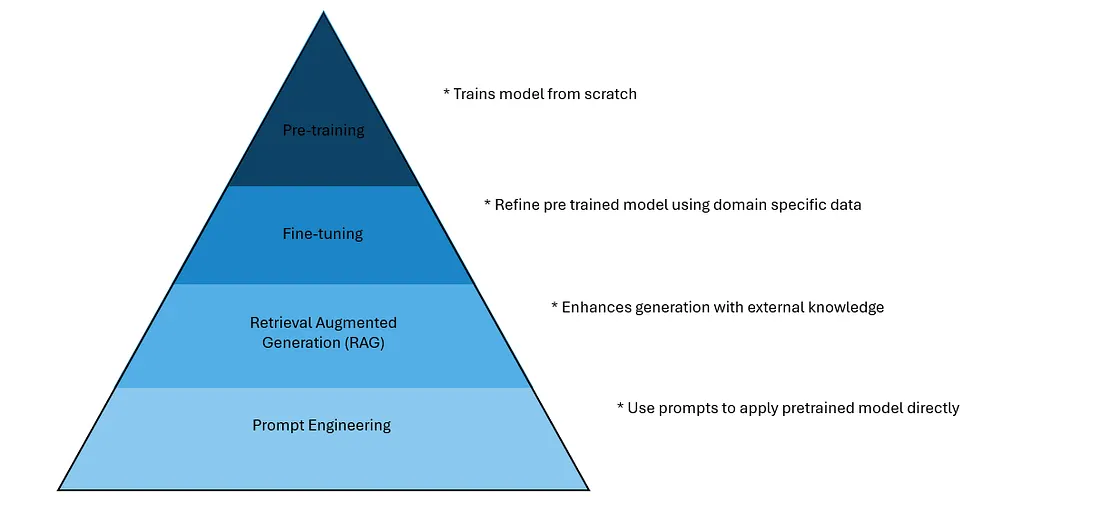

### Pretraining

czyli trenowanie modelu językowego od zera

In [8]:
from transformers import BertConfig, BertForMaskedLM

# Tworzymy pusty model
config = BertConfig(
    vocab_size=30522,
    hidden_size=256,
    num_hidden_layers=4,
    num_attention_heads=4,
    intermediate_size=512
)

model = BertForMaskedLM(config)


Model uczy się ogólnych zależności językowych, np. jakie słowa występują razem.
Nie ma tu żadnych etykiet ani konkretnego zadania - ten etap jest często bardzo kosztowyny. Z powodu zasobów na  zajęciach nie pretrenujemy modeli

### Fine-tuning

czyli dostosowanie do konkretnego zadania (np. klasyfikacji sentymentu)

In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import load_dataset
import numpy as np
import evaluate

# Wczytanie danych (IMDb)
dataset = load_dataset("imdb")
small_train = dataset["train"].shuffle(seed=42).select(range(2000))
small_test = dataset["test"].shuffle(seed=42).select(range(500))

# Tokenizacja
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=128)

train_enc = small_train.map(tokenize, batched=True)
test_enc = small_test.map(tokenize, batched=True)

model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return accuracy.compute(predictions=preds, references=labels)

# Trening
training_args = TrainingArguments(
    output_dir="./fine_tuning",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_enc,
    eval_dataset=test_enc,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)

trainer.train()
trainer.evaluate()

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/var/folders/dz/k1yrw7ln77l1qks16zv0lh7w0000gn/T/ipykernel_22671/118244944.py:38: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/opt/anaconda3/envs/NLP_PJN/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.389347,0.820000


/opt/anaconda3/envs/NLP_PJN/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/NLP_PJN/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 0.3893466591835022,
 'eval_accuracy': 0.82,
 'eval_runtime': 1.6185,
 'eval_samples_per_second': 308.919,
 'eval_steps_per_second': 38.924,
 'epoch': 1.0}

Uczymy ten sam model na nowym zadaniu (tu: klasyfikacja sentymentu).
Całe wagi modelu mogą być aktualizowane, lub tylko część.

In [10]:
texts = [
    "I really enjoyed this movie, it was awesome!",
    "This film was boring and too long."
]

inputs = tokenizer(texts, padding=True, truncation=True, return_tensors="pt").to(trainer.model.device)

outputs = trainer.model(**inputs)

import torch
preds = torch.nn.functional.softmax(outputs.logits, dim=-1)
labels = torch.argmax(preds, dim=1)

print(preds)
print(labels)

tensor([[0.0558, 0.9442],
        [0.9326, 0.0674]], device='mps:0', grad_fn=<SoftmaxBackward0>)
tensor([1, 0], device='mps:0')


### RAG

RAG = Retrieval-Augmented Generation
Model generatywny (np. BERT, GPT, T5) ma dostęp do zewnętrznej bazy wiedzy (dokumentów, notatek, artykułów):
1. Retriever wyszukuje najbardziej podobne fragmenty tekstu,
2. Generator wykorzystuje je do stworzenia odpowiedzi.

O RAGach już niedługo :)

### Prompt-tuning

czyli użycie gotowych modeli bez ich trenowania, tylko z pomocą promptów

In [11]:
from transformers import pipeline

generator = pipeline("text2text-generation", model="google/flan-t5-small")

prompt_good = "Classify the sentiment of the following movie review as 'positive' or 'negative': This movie was great and full of emotions."
result = generator(prompt_good, max_new_tokens=20)

print(result)


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Device set to use mps:0


[{'generated_text': 'positive'}]


In [12]:
prompt_bad = "This movie was great and full of emotions. What do you think?"
print(generator(prompt_bad, max_new_tokens=30))

[{'generated_text': 'This movie was great and full of emotions. It was great and full of emotions. It was great and full of emotions. It was great and full'}]


### Podsumowanie

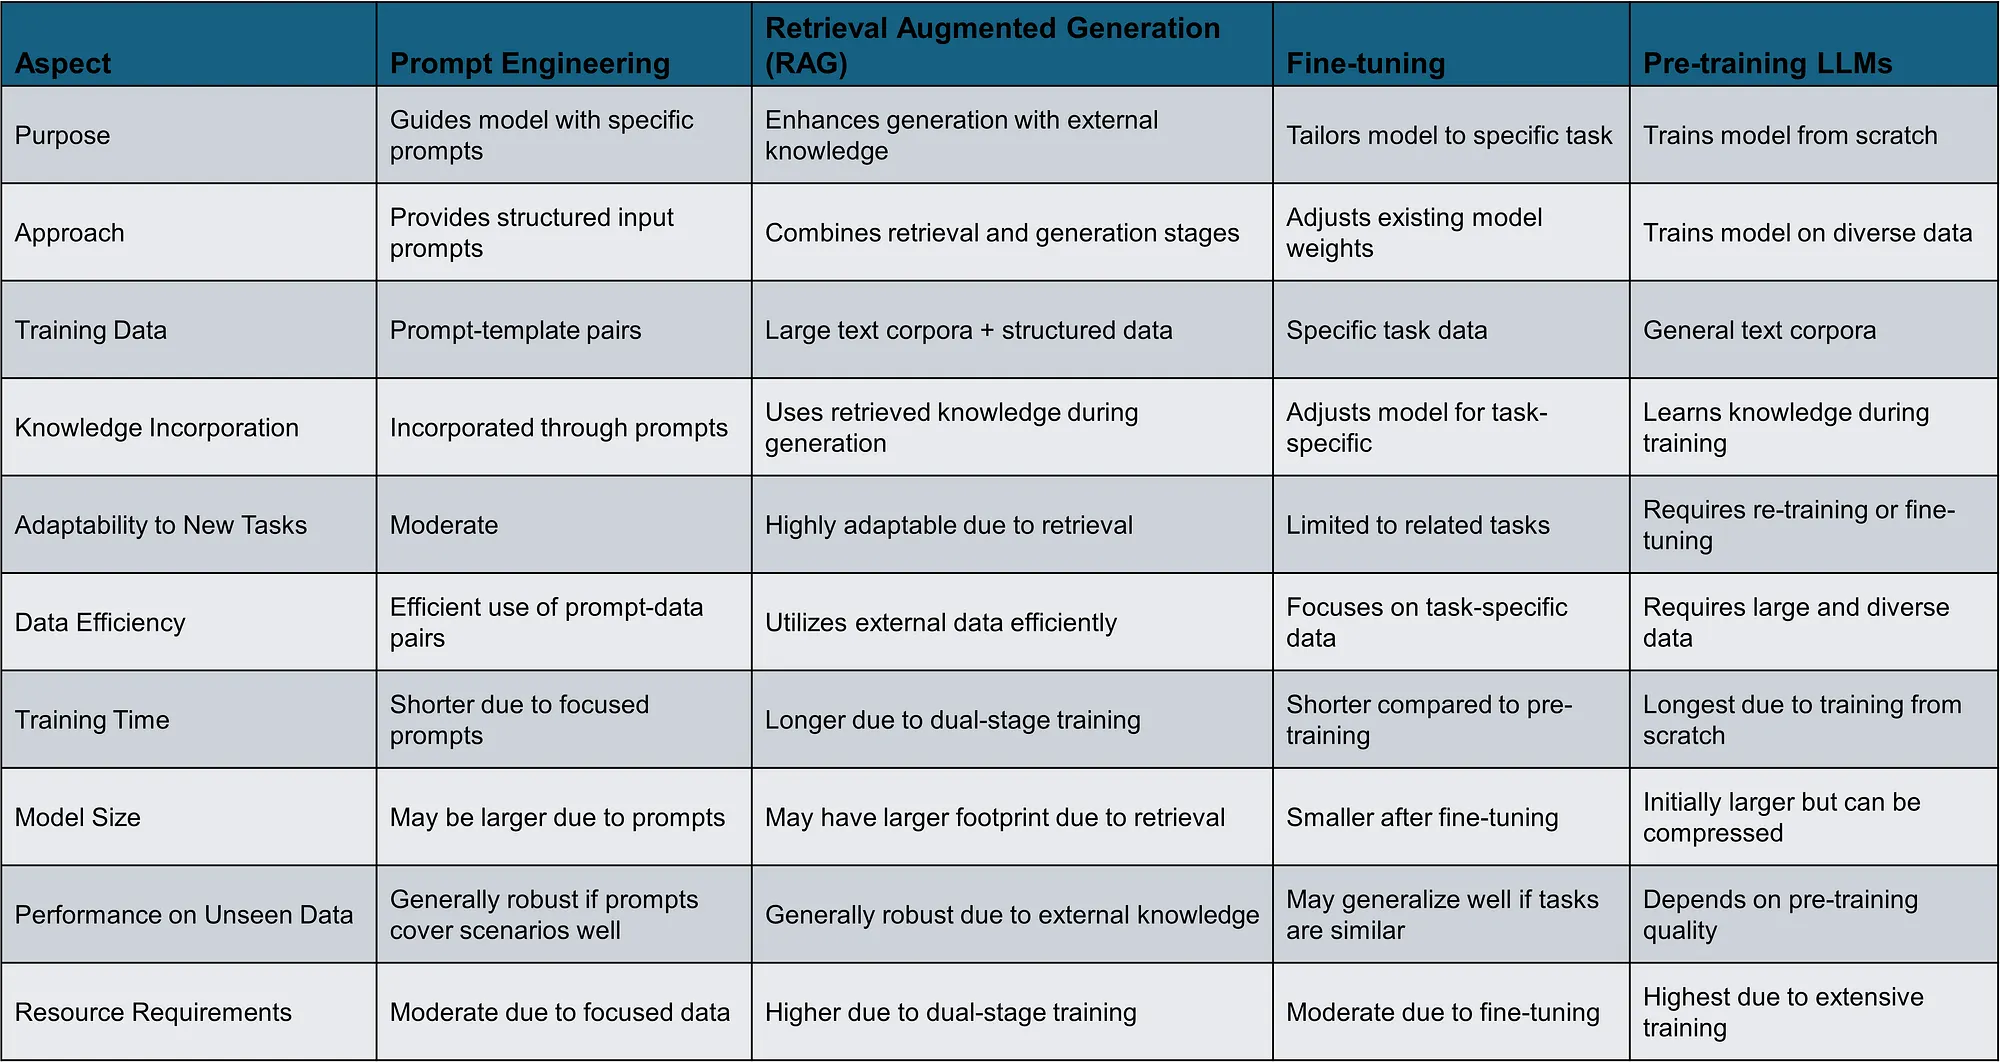

> Więcej o tych 4 metodach: https://medium.com/@jainpalak9509/use-llms-pre-training-fine-tuning-rag-and-prompt-engineering-564d5670f44d

## LoRA

LoRA (Low-Rank Adaptation) to metoda efektywnego dostrajania (fine-tuningu) dużych modeli językowych.
Zamiast aktualizować wszystkie miliony parametrów modelu (np. GPT, BERT), LoRA wprowadza małe, dodatkowe macierze, które uczą się zmian, a oryginalne wagi modelu pozostają zamrożone.

### Jak działa LoRA?

Wyobraź sobie, że masz już gotowy model (np. BERT), który zna język ogólnie, ale chcesz, żeby lepiej rozumiał np. język prawniczy.

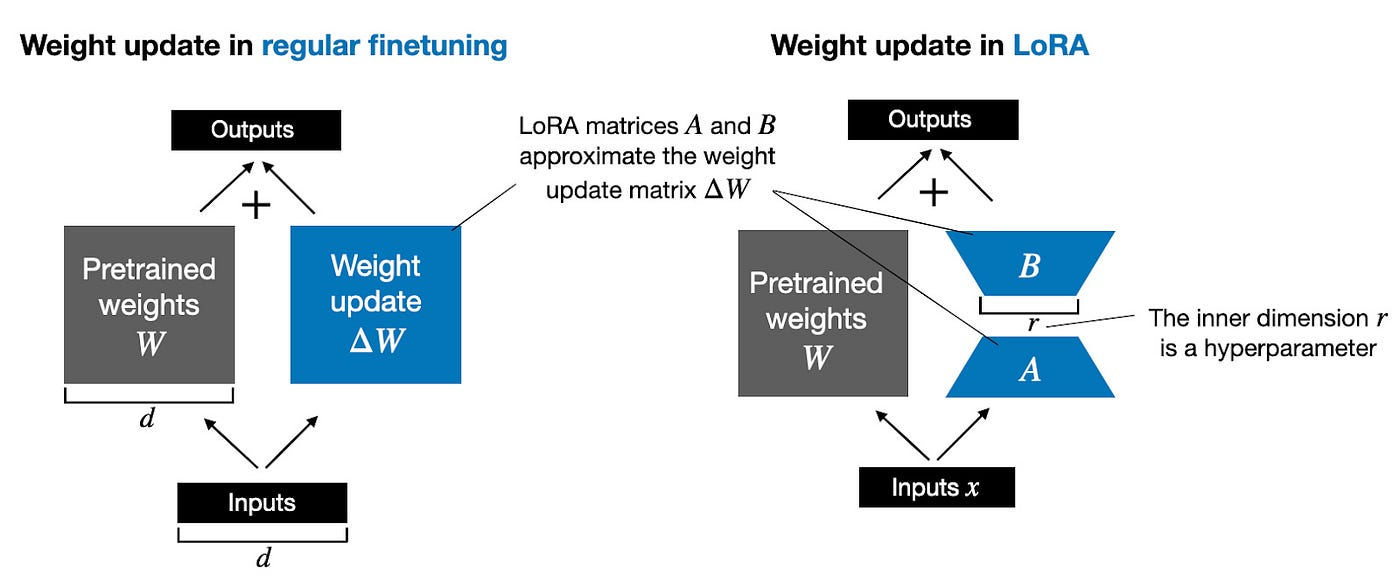

LoRA zamraża oryginalne parametry modelu,
a następnie dodaje małe, dodatkowe macierze (A i B), które uczą się nowych informacji.


Macierz Weight update może być rozbita w ten sposób:

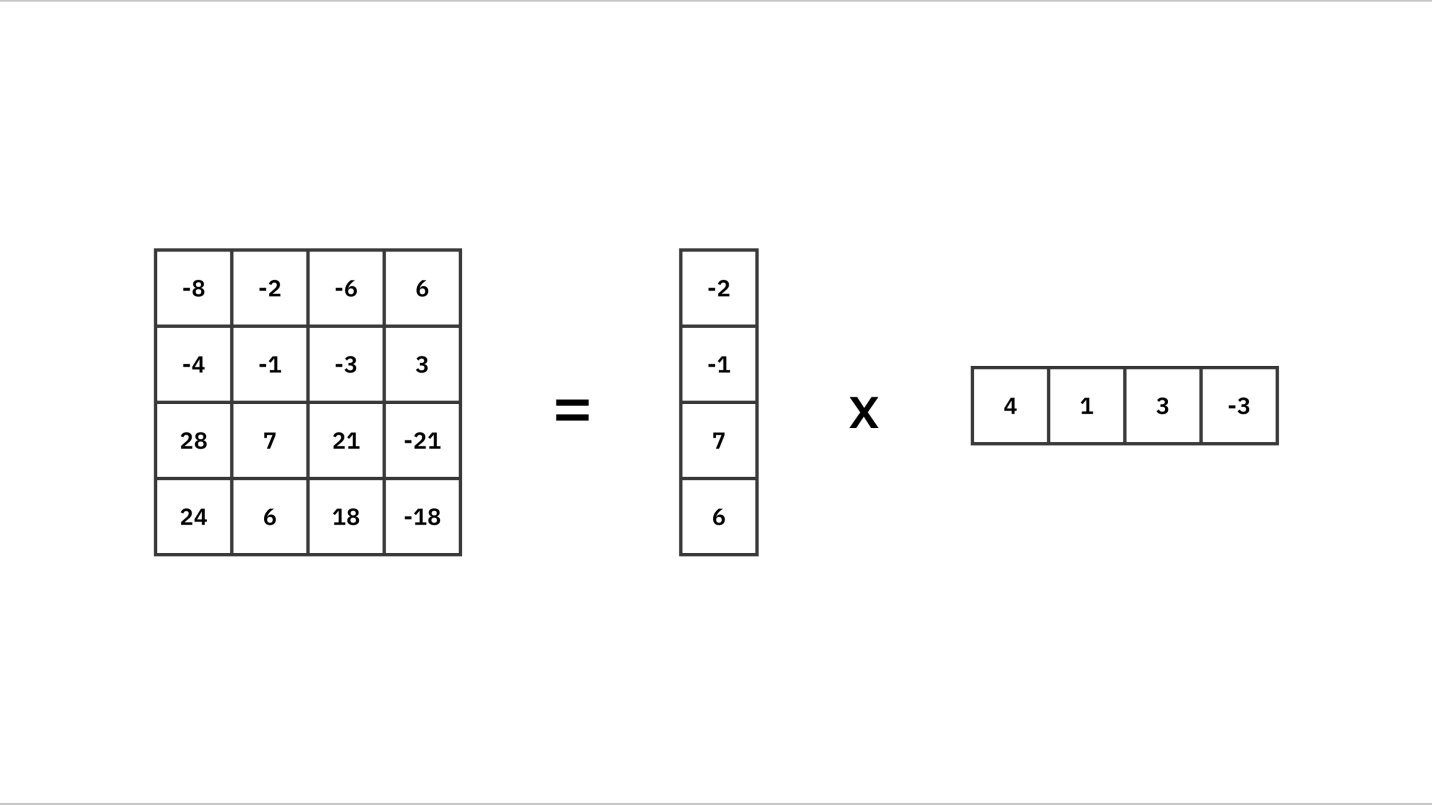

Przykład:
Mamy model, gdzie delta W ma 10 000 rzędó i 20 000 kolumn. To daje nam razem 200 000 000 parametrów - dużo!

Możemy zaplanować, że nasza macierz A będzie miała 10 000 rzędó na r = 8 kolumn. Wtedy B ma r = 8 rzedó i 20 000 kolumn. W tej sytuacji mamy 10 000 * 8 + 20 000 * 8 parametrów = 240 000 parametrów (około 830 raza mniej niż na początku!)

Na końcu, po treningu, LoRA łączy te małe poprawki z oryginalnym modelem —
otrzymujemy nową, lepiej dopasowaną wersję modelu.

| Zalety                                                    | Ograniczenia                                             |
| --------------------------------------------------------- | -------------------------------------------------------- |
| Szybszy trening                                        | Nadal wymaga pewnych zasobów GPU                      |
| Mało pamięci (uczy tylko małe macierze)                | Nie zawsze działa równie dobrze jak pełny fine-tuning |
| Możliwość łączenia kilku LoRA z jednym modelem bazowym | Trudniejsze debugowanie (więcej warstw pośrednich)    |

> Więcej o LoRA: https://www.ibm.com/think/topics/lora


# Zadanie

🎯 Użyj LoRA do zfine tunowania modelu na datasetcie "Abirate/english_quotes".

1. Model:` model_name = "distilgpt2"`
2. Zanim dodasz LoRa musimy zamrozić parametry modelu (Podpowiedź: coś musi mieć requires_grad na False lub możemy użyć mark_only_lora_as_trainable)
3. Konfiguracja LoRA:
  - używamy LoraConfig z biblioteki peft
  - Musimy ustawić r = 8 (wymiar low-rank)
4. Używamy datasetu o angielskich cytatach: data = `load_dataset("Abirate/english_quotes")` (Podpowiedź: będzie trzeba ztokenizować ten zbiór ;) )
5. Trenujemy przy użyciu TrainingArguments i Trainer. Ustawimy nie epoki a kroki: `max_steps=1000`
6. Przetestuj wytrenowany model


In [15]:
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

#Model
model_name = "distilgpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(model_name)

# zamrażanie oryginalnych wag modelu
for param in model.parameters():
    param.requires_grad = False

config = LoraConfig(
    r=8
)

model = get_peft_model(model, config)

# Sprawdźmy ile parametrów będziemy trenować - tutaj musimy już mieć model wraz z configiem LoraConfig
def print_trainable_parameters(model):
    trainable_params = 0
    all_param = 0
    for _, param in model.named_parameters():
        all_param += param.numel()
        if param.requires_grad:
            trainable_params += param.numel()
    print(f"Parametry do treningu: {trainable_params:,} / {all_param:,} ({100 * trainable_params / all_param:.2f}%)")

print_trainable_parameters(model)

# Data
data = load_dataset("Abirate/english_quotes")

def preprocess_example(example):
    # Musimy połaczyć elementy z datasetu w jedność - qoutes + author + tags
    example["text"] = example["quote"] + " - " + example["author"] + " (" + ", ".join(example["tags"]) + ")"
    return example

def tokenize_fn(examples):
    return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=128)

data = data.map(preprocess_example)
tokenized = data.map(tokenize_fn, batched=True, remove_columns=data["train"].column_names)

training_args = TrainingArguments(
    output_dir="./lora",
    max_steps=1000,
    per_device_train_batch_size=8,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    data_collator=DataCollatorForLanguageModeling(tokenizer, mlm=False),
)

model.config.use_cache = False
trainer.train()

# Test
prompt = "Training models with LoRa is "
inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

model.eval()
with torch.no_grad():
    output = model.generate(**inputs, max_new_tokens=40, temperature=0.8)

print("\n💬 Model output:\n", tokenizer.decode(output[0], skip_special_tokens=True))

/opt/anaconda3/envs/NLP_PJN/lib/python3.12/site-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


Parametry do treningu: 147,456 / 82,060,032 (0.18%)


/opt/anaconda3/envs/NLP_PJN/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
500,3.842300
1000,3.558400


/opt/anaconda3/envs/NLP_PJN/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.



💬 Model output:
 Training models with LoRa is  a great way to get started with the basics of LoRa.
 The first thing you need to know is how to get started with LoRa. The first thing you need to know
